# code_133 · Operator cases, field sampling and query contracts

**Book:** section 26.1. A self-contained operator-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_26_GUIDE.md), [run evidence](../CHAPTER_26_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_133).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3133;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3133


<a id="operator-case-contract"></a>
 ## A case is a complete physical input function pair
 Generate source64/development16/final32 independent Dirichlet bar problems on[0,1], plus32 changed-frequency forcing cases. Each case has a positive coefficient field and a load field; native finite-volume solves map them to displacement. Three material and four forcing coefficients generate smooth fields. A fixed-grid multioutput Ridge sees32 samples of each input function and predicts65 fixed output locations. Source-only preprocessing and alpha0.001/0.1/10 selection use whole development cases. The final129-grid check interpolates the fixed output vector; this is not a coordinate-query neural operator or proof of resolution invariance. A separate exact constant-coefficient witness has two forcing functions indistinguishable at the32 input sensors but different solutions.


{'case_counts': [64, 16, 32, 32], 'input_sensor_count_per_field': 32, 'input_channels': ['positive coefficient', 'forcing'], 'fixed_output_locations': 65, 'finer_output_locations': 129, 'selected_alpha': 0.001, 'candidates': [{'alpha': 0.001, 'development_MSE': 0.00023755158521376416}, {'alpha': 0.1, 'development_MSE': 0.00024924421772019796}, {'alpha': 10.0, 'development_MSE': 0.0002693565497898392}], 'final_fixed_grid_MSE': 0.0006290578449163966, 'changed_frequency_MSE': 0.0004351470573704551, 'final_interpolated_fine_grid_MSE': 0.0006337214128244511, 'reference_65_vs_129_grid_RMS': 1.3755328684900674e-05, 'input_alias_max_difference': 1.4210854715202004e-14, 'unidentifiable_solution_max_difference': 0.00010543307350919646}


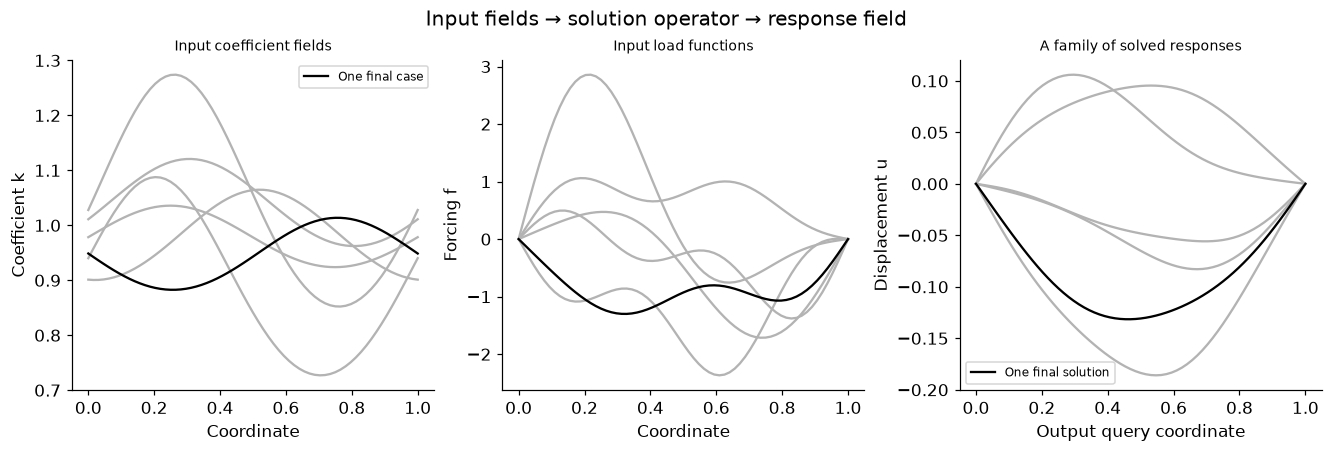

In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
coefficients=rng.normal(0,1,(144,7));sensors=np.linspace(0,1,32);grid=np.linspace(0,1,65)
def fields(c,x,shift=False):
    k=np.exp(.2*c[0]+.15*c[1]*np.sin(2*np.pi*x)+.1*c[2]*np.cos(2*np.pi*x));modes=np.array([1,2,6,8] if shift else [1,2,3,4]);f=np.sum(c[3:,None]*np.sin(np.pi*modes[:,None]*x[None,:])/modes[:,None],axis=0);return k,f
def solve(c,n,shift=False):
    h=1/(n+1);x=np.arange(1,n+1)*h;edge=(np.arange(n+1)+.5)*h;k,_=fields(c,edge,shift);_,f=fields(c,x,shift);K=np.diag((k[:-1]+k[1:])/h**2)+np.diag(-k[1:-1]/h**2,1)+np.diag(-k[1:-1]/h**2,-1);return np.r_[0,x,1],np.r_[0,np.linalg.solve(K,f),0]
inputs=np.stack([np.concatenate(fields(c,sensors,j>=112)) for j,c in enumerate(coefficients)]);targets=np.stack([solve(c,63,j>=112)[1] for j,c in enumerate(coefficients)]);choices=[]
for alpha in [.001,.1,10.]:
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha));model.fit(inputs[:64],targets[:64]);pred=model.predict(inputs);score=float(np.mean((pred[64:80]-targets[64:80])**2));choices.append((score,alpha,model,pred))
score,alpha,model,pred=min(choices,key=lambda x:x[0]);fine_grid=np.linspace(0,1,129);fine_reference=np.stack([solve(c,127,j>=112)[1] for j,c in enumerate(coefficients)]);interpolated=np.stack([np.interp(fine_grid,grid,u) for u in pred]);refinement=float(np.sqrt(np.mean((targets[80:112]-fine_reference[80:112,::2])**2)))
witness_a=np.sin(np.pi*sensors);witness_b=witness_a+np.sin(31*np.pi*sensors);np.testing.assert_allclose(witness_a,witness_b,atol=2e-14,rtol=0);query=np.linspace(0,1,1001);solution_difference=np.sin(31*np.pi*query)/(31*np.pi)**2;assert np.max(np.abs(solution_difference))>1e-4
assert set(range(64)).isdisjoint(range(64,80)) and set(range(80,112)).isdisjoint(range(112,144));assert np.all(targets[:,[0,-1]]==0)
RESULTS.update(case_counts=[64,16,32,32],input_sensor_count_per_field=32,input_channels=['positive coefficient','forcing'],fixed_output_locations=65,finer_output_locations=129,selected_alpha=alpha,candidates=[{'alpha':x[1],'development_MSE':x[0]} for x in choices],final_fixed_grid_MSE=float(np.mean((pred[80:112]-targets[80:112])**2)),changed_frequency_MSE=float(np.mean((pred[112:]-targets[112:])**2)),final_interpolated_fine_grid_MSE=float(np.mean((interpolated[80:112]-fine_reference[80:112])**2)),reference_65_vs_129_grid_RMS=refinement,input_alias_max_difference=float(np.max(np.abs(witness_a-witness_b))),unidentifiable_solution_max_difference=float(np.max(np.abs(solution_difference))));print(RESULTS)
fig,axes=plt.subplots(1,3,figsize=(12,4));fig.suptitle('Input fields → solution operator → response field')
for j in range(5):
    k,f=fields(coefficients[j],grid);axes[0].plot(grid,k,color='.7');axes[1].plot(grid,f,color='.7');axes[2].plot(grid,targets[j],color='.7')
k,f=fields(coefficients[80],grid);axes[0].plot(grid,k,'k-',label='One final case');axes[1].plot(grid,f,'k-');axes[2].plot(grid,targets[80],'k-',label='One final solution');axes[0].set(xlabel='Coordinate',ylabel='Coefficient k',title='Input coefficient fields');axes[1].set(xlabel='Coordinate',ylabel='Forcing f',title='Input load functions');axes[2].set(xlabel='Output query coordinate',ylabel='Displacement u',title='A family of solved responses');axes[0].legend(fontsize=8);axes[2].legend(fontsize=8);plt.show()


<a id="sampling-and-transfer"></a>
 ## More output queries do not add missing input information
 The Ridge estimator has a fixed64-dimensional sampled input and65-dimensional output. It cannot directly accept a new input sensor count without a declared transformation. Interpolating its output is a numerical adapter, not evidence that it learned a sampling-independent function-space map. Whole parameter cases remain separate throughout selection. The alias witness uses a constant coefficient and exact sine solutions, independently of the variable-coefficient dataset: its missing high-frequency input component is a sampling limitation, not a Ridge-specific failure. All function spaces, boundary conditions and changed-frequency support are declared rather than inferred from one successful picture.


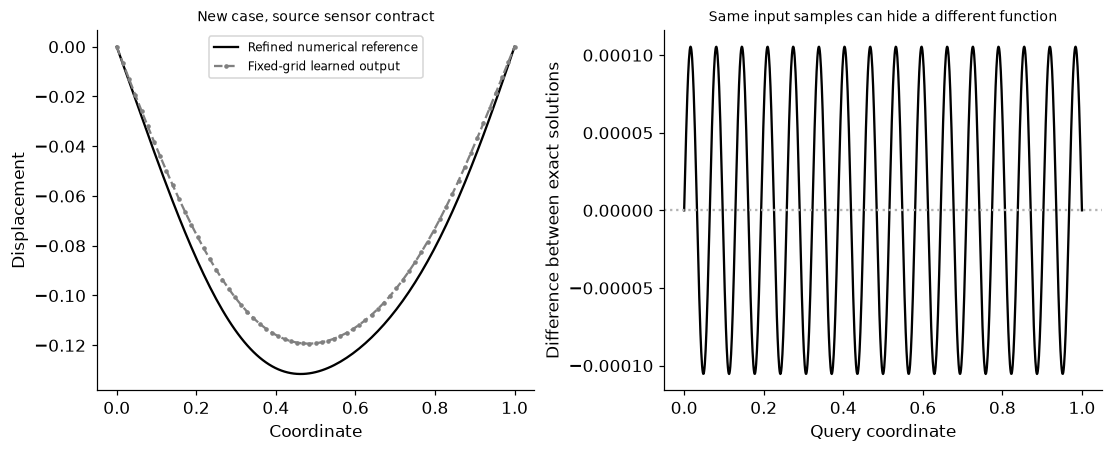

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));j=80;axes[0].plot(fine_grid,fine_reference[j],'k-',label='Refined numerical reference');axes[0].plot(grid,pred[j],'o--',color='.5',markersize=2,label='Fixed-grid learned output');axes[0].set(xlabel='Coordinate',ylabel='Displacement',title='New case, source sensor contract');axes[0].legend(fontsize=8);axes[1].plot(query,solution_difference,color='black');axes[1].axhline(0,color='.7',linestyle=':');axes[1].set(xlabel='Query coordinate',ylabel='Difference between exact solutions',title='Same input samples can hide a different function');plt.show()
assert np.isfinite(RESULTS['final_fixed_grid_MSE'])


In [4]:
summary={'example_id':'code_133','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual variable-coefficient solution family', 'whole-problem fitting and assessment', 'finite-grid Ridge operator reference', 'independent mesh refinement', 'input-sensor alias nonidentifiability'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual variable-coefficient solution family", "whole-problem fitting and assessment", "finite-grid Ridge operator reference", "independent mesh refinement", "input-sensor alias nonidentifiability"], "elapsed_seconds": 1.023, "example_id": "code_133", "hardware": "Darwin arm64 CPU", "results": {"candidates": [{"alpha": 0.001, "development_MSE": 0.00023755158521376416}, {"alpha": 0.1, "development_MSE": 0.00024924421772019796}, {"alpha": 10.0, "development_MSE": 0.0002693565497898392}], "case_counts": [64, 16, 32, 32], "changed_frequency_MSE": 0.0004351470573704551, "final_fixed_grid_MSE": 0.0006290578449163966, "final_interpolated_fine_grid_MSE": 0.0006337214128244511, "finer_output_locations": 129, "fixed_output_locations": 65, "input_alias_max_difference": 1.4210854715202004e-14, "input_channels": ["positive coefficient", "forcing"], "input_sensor_count_per_field": 32, "reference_65_vs_129_grid_RMS": 1.3755328684900674e-05, "selected_